# Phase 06: Model Training & Evaluation
**AI-Powered Transaction Risk Scoring System**

### Notebook Objective
This notebook demonstrates the end-to-end training, hyperparameter configuration, threshold optimization, and comprehensive evaluation of the **XGBoost Fraud Classifier**.

### Key Milestones:
1. **Processed Data Ingestion:** Load 70% Train (198,608), 15% Validation (42,559), and 15% Test (42,559) processed partitions.
2. **Dynamic Class Imbalance Weighting:** Calculate dynamic `scale_pos_weight` ($N_{\text{neg}} / N_{\text{pos}} = 599.02$) on the training partition.
3. **XGBoost Training:** Train an explicit gradient boosted tree model using histogram-based splitting (`tree_method='hist'`).
4. **Threshold Optimization on Validation Set:** Sweep decision thresholds $[0.05, 0.95]$ on validation predictions to maximize the validation $F_1$-score.
5. **Unbiased Generalization on Test Set:** Evaluate the optimized model on the untouched test partition.
6. **Visual Diagnostics:** Plot Precision-Recall curve, ROC curve, Threshold vs Metrics curve, and Confusion Matrix.
7. **Feature Importance:** Analyze the top discriminative signals learned by the gradient boosting model.
8. **Serialization & Metadata Export:** Persist `fraud_model.joblib` and structured `model_metadata.json`.


In [1]:
import sys
from pathlib import Path

# Add project root to sys.path for modular imports
project_root = Path.cwd().resolve().parent.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

from ml.src.config import (
    TRAIN_DATA_FILE,
    VAL_DATA_FILE,
    TEST_DATA_FILE,
    FRAUD_MODEL_ARTIFACT_FILE,
    MODEL_METADATA_FILE,
    RANDOM_SEED,
    TARGET_COLUMN,
)
from ml.src.training.train import (
    load_processed_data,
    train_model,
    save_model,
    load_model,
    save_model_metadata,
)
from ml.src.training.metrics import (
    calculate_class_weight,
    compute_classification_metrics,
    sweep_thresholds,
    find_optimal_threshold,
)
from ml.src.training.evaluate import (
    evaluate_model,
    generate_threshold_analysis,
)

print(f"Project Root: {project_root}")
print(f"Train File:   {TRAIN_DATA_FILE}")


Project Root: E:\Project\AI Transaction Risk System
Train File:   E:\Project\AI Transaction Risk System\ml\data\processed\train.csv


## 1. Load Processed Datasets

We load the processed training, validation, and testing partitions produced in Phase 05.

In [2]:
X_train, y_train = load_processed_data(TRAIN_DATA_FILE)
X_val, y_val = load_processed_data(VAL_DATA_FILE)
X_test, y_test = load_processed_data(TEST_DATA_FILE)

print("Dataset Partition Shapes:")
print(f"  X_train: {X_train.shape}, y_train fraud count: {(y_train == 1).sum()} ({(y_train == 1).mean():.5%})")
print(f"  X_val:   {X_val.shape}, y_val fraud count:   {(y_val == 1).sum()} ({(y_val == 1).mean():.5%})")
print(f"  X_test:  {X_test.shape}, y_test fraud count:  {(y_test == 1).sum()} ({(y_test == 1).mean():.5%})")
print(f"  Input Features ({len(X_train.columns)}): {list(X_train.columns)}")


Dataset Partition Shapes:
  X_train: (198608, 31), y_train fraud count: 331 (0.16666%)
  X_val:   (42559, 31), y_val fraud count:   71 (0.16683%)
  X_test:  (42559, 31), y_test fraud count:  71 (0.16683%)
  Input Features (31): ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'hour_sin', 'hour_cos', 'amount_log']


## 2. Dynamic Class Imbalance Weighting

Because fraud represents only ~0.17% of transactions (imbalance ratio ~599:1), unweighted cross-entropy loss would prioritize legitimate transactions and miss fraud instances.

We dynamically compute `scale_pos_weight` directly from the training set:
$$\text{scale\_pos\_weight} = \frac{N_{\text{legitimate}}}{N_{\text{fraud}}} = \frac{198,277}{331} = 599.02$$


In [3]:
scale_pos_weight = calculate_class_weight(y_train)
print(f"Calculated Dynamic scale_pos_weight: {scale_pos_weight:.4f}")


Calculated Dynamic scale_pos_weight: 599.0242


## 3. Train XGBoost Classifier

We train an explicitly configured `xgboost.XGBClassifier` with:
- `n_estimators = 200`
- `max_depth = 5`
- `learning_rate = 0.05`
- `subsample = 0.8`
- `colsample_bytree = 0.8`
- `min_child_weight = 3`
- `scale_pos_weight = 599.02`
- `tree_method = 'hist'`


In [4]:
model = train_model(
    X_train,
    y_train,
    X_val=X_val,
    y_val=y_val,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_SEED,
)

print("XGBoost Model Training Completed Successfully.")


XGBoost Model Training Completed Successfully.


## 4. Validation Set Evaluation & Threshold Sweep

Using `scale_pos_weight = 599.02` scales gradient penalties, shifting raw fraud probabilities upwards. Applying the default naive threshold ($0.5$) without tuning would lead to excessive false alarms.

We perform a systematic threshold sweep on the **Validation Set** to find the decision threshold that maximizes the validation $F_1$-score.

In [5]:
sweep_df, optimal_threshold, val_metrics_optimal = generate_threshold_analysis(
    model,
    X_val,
    y_val,
    criterion="max_f1",
)

val_metrics_default, val_probs = evaluate_model(model, X_val, y_val, threshold=0.5)

print(f"Validation Optimal Threshold (Max F1): {optimal_threshold:.4f}")
display(sweep_df.head(10))


Validation Optimal Threshold (Max F1): 0.9500


,threshold,precision,recall,f1_score,accuracy,true_negatives,false_positives,false_negatives,true_positives
0,0.05,0.137856,0.887324,0.238636,0.990554,42094,394,8,63
1,0.10,0.245059,0.873239,0.382716,0.995301,42297,191,9,62
2,0.15,0.373494,0.873239,0.523207,0.997345,42384,104,9,62
3,0.20,0.437956,0.845070,0.576923,0.997932,42411,77,11,60
4,0.25,0.483607,0.830986,0.611399,0.998238,42425,63,12,59
5,0.30,0.561905,0.830986,0.670455,0.998637,42442,46,12,59
6,0.35,0.595960,0.830986,0.694118,0.998778,42448,40,12,59
7,0.40,0.644444,0.816901,0.720497,0.998943,42456,32,13,58
8,0.45,0.674419,0.816901,0.738854,0.999037,42460,28,13,58
9,0.50,0.707317,0.816901,0.758170,0.999131,42464,24,13,58


### Validation Performance Comparison: Default (0.5) vs. Tuned Threshold

In [6]:
val_comparison = pd.DataFrame([
    {
        "Strategy": "Default Threshold (0.50)",
        "Threshold": 0.50,
        "Precision": f"{val_metrics_default.precision:.4f}",
        "Recall": f"{val_metrics_default.recall:.4f}",
        "F1-Score": f"{val_metrics_default.f1_score:.4f}",
        "ROC-AUC": f"{val_metrics_default.roc_auc:.4f}",
        "PR-AUC": f"{val_metrics_default.pr_auc:.4f}",
        "FP (False Alarms)": val_metrics_default.false_positives,
        "FN (Missed Fraud)": val_metrics_default.false_negatives,
    },
    {
        "Strategy": f"Optimized Threshold ({optimal_threshold:.2f})",
        "Threshold": optimal_threshold,
        "Precision": f"{val_metrics_optimal.precision:.4f}",
        "Recall": f"{val_metrics_optimal.recall:.4f}",
        "F1-Score": f"{val_metrics_optimal.f1_score:.4f}",
        "ROC-AUC": f"{val_metrics_optimal.roc_auc:.4f}",
        "PR-AUC": f"{val_metrics_optimal.pr_auc:.4f}",
        "FP (False Alarms)": val_metrics_optimal.false_positives,
        "FN (Missed Fraud)": val_metrics_optimal.false_negatives,
    }
])

display(val_comparison)


,Strategy,Threshold,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,FP (False Alarms),FN (Missed Fraud)
0,Default Threshold (0.50),0.50,0.7073,0.8169,0.7582,0.9752,0.8329,24,13
1,Optimized Threshold (0.95),0.95,0.9455,0.7324,0.8254,0.9752,0.8329,3,19


## 5. Unbiased Evaluation on Untouched Test Partition

Having selected the decision threshold **strictly on the validation set**, we now evaluate the model on the untouched test partition (`42,559` samples, `71` fraud).

In [7]:
test_metrics_optimal, test_probs = evaluate_model(
    model, X_test, y_test, threshold=optimal_threshold
)
test_metrics_default, _ = evaluate_model(
    model, X_test, y_test, threshold=0.5
)

test_comparison = pd.DataFrame([
    {
        "Evaluation": "Test Set @ Default (0.50)",
        "Precision": f"{test_metrics_default.precision:.4f}",
        "Recall": f"{test_metrics_default.recall:.4f}",
        "F1-Score": f"{test_metrics_default.f1_score:.4f}",
        "ROC-AUC": f"{test_metrics_default.roc_auc:.4f}",
        "PR-AUC": f"{test_metrics_default.pr_auc:.4f}",
        "TN": test_metrics_default.true_negatives,
        "FP": test_metrics_default.false_positives,
        "FN": test_metrics_default.false_negatives,
        "TP": test_metrics_default.true_positives,
    },
    {
        "Evaluation": f"Test Set @ Tuned ({optimal_threshold:.2f})",
        "Precision": f"{test_metrics_optimal.precision:.4f}",
        "Recall": f"{test_metrics_optimal.recall:.4f}",
        "F1-Score": f"{test_metrics_optimal.f1_score:.4f}",
        "ROC-AUC": f"{test_metrics_optimal.roc_auc:.4f}",
        "PR-AUC": f"{test_metrics_optimal.pr_auc:.4f}",
        "TN": test_metrics_optimal.true_negatives,
        "FP": test_metrics_optimal.false_positives,
        "FN": test_metrics_optimal.false_negatives,
        "TP": test_metrics_optimal.true_positives,
    }
])

display(test_comparison)


,Evaluation,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Test Set @ Default (0.50),0.7403,0.8028,0.7703,0.9656,0.7761,42468,20,14,57
1,Test Set @ Tuned (0.95),0.8333,0.7746,0.8029,0.9656,0.7761,42477,11,16,55


## 6. Comprehensive Evaluation Visualizations

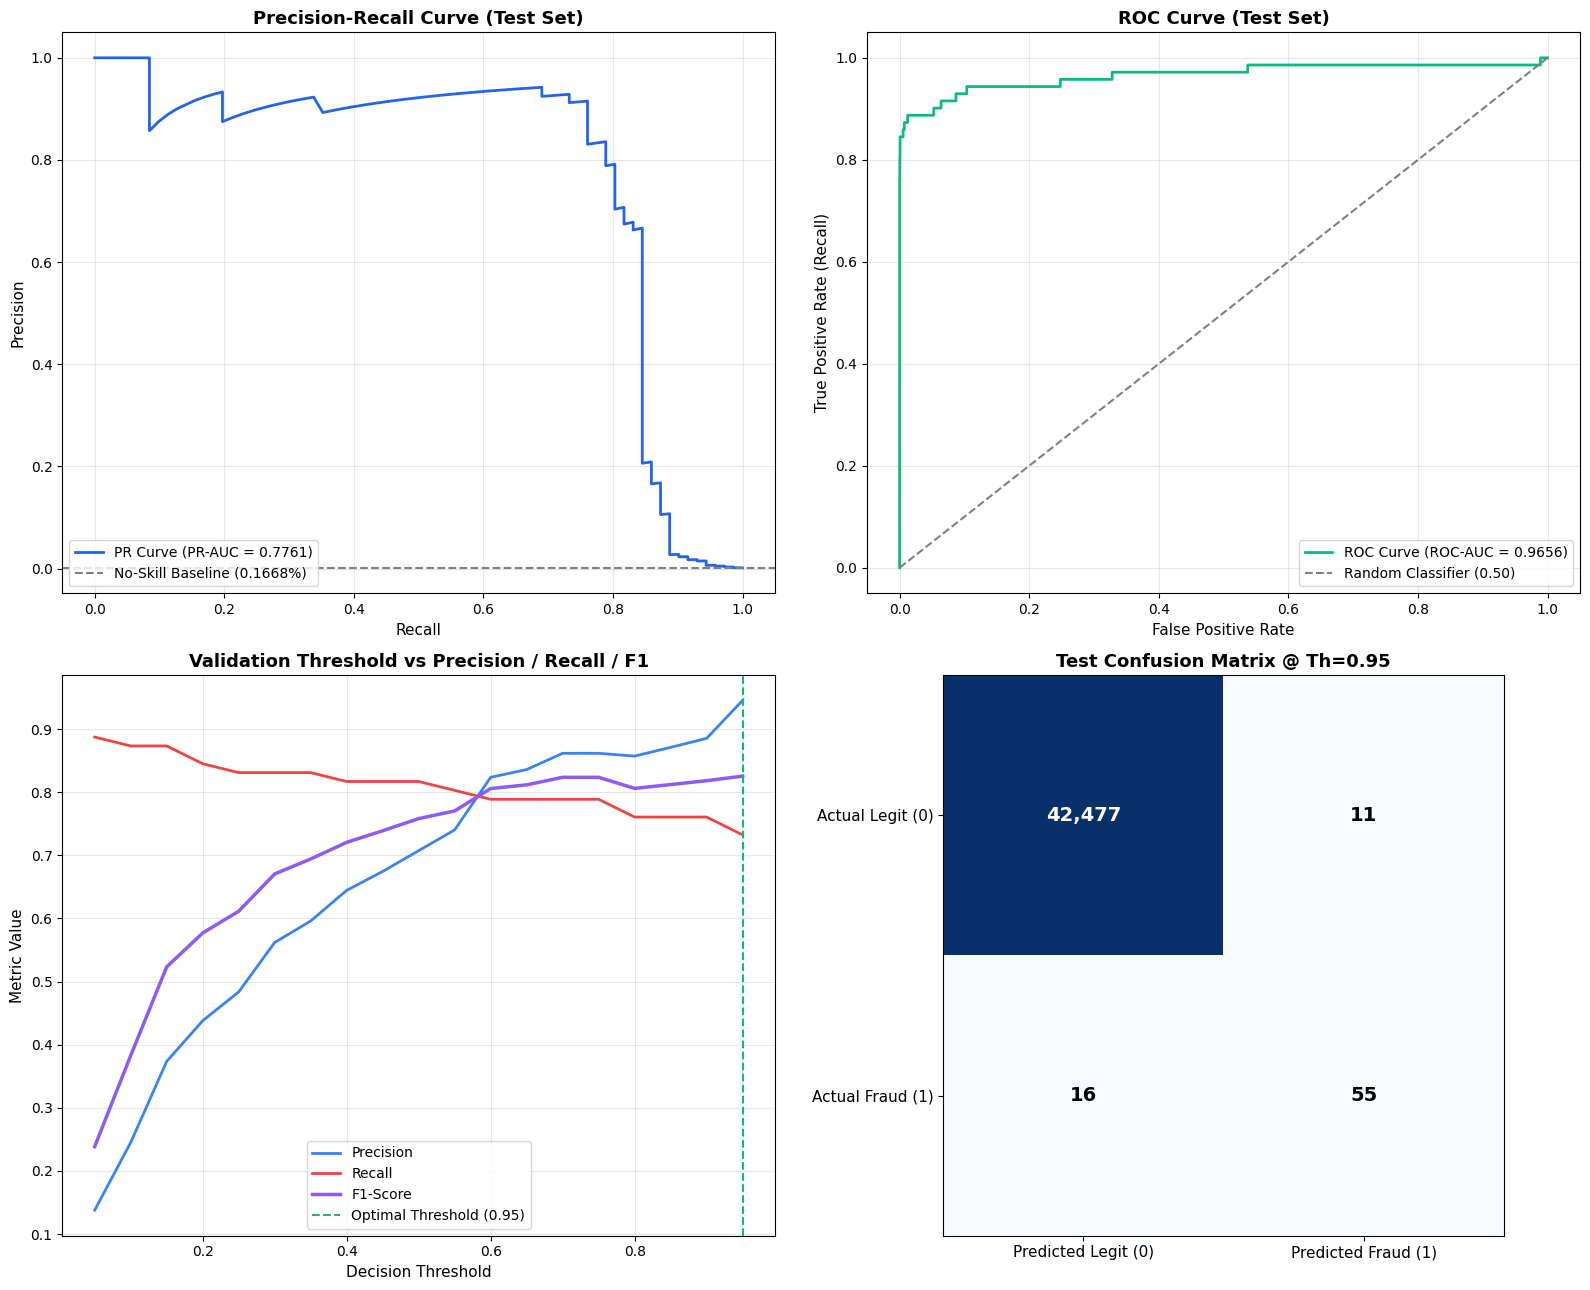

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# 1. Precision-Recall Curve (PR-AUC)
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, test_probs)
axes[0, 0].plot(recalls, precisions, color="#2563eb", lw=2, label=f"PR Curve (PR-AUC = {test_metrics_optimal.pr_auc:.4f})")
axes[0, 0].axhline(y=(y_test == 1).mean(), color="gray", linestyle="--", label=f"No-Skill Baseline ({(y_test == 1).mean():.4%})")
axes[0, 0].set_title("Precision-Recall Curve (Test Set)", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Recall", fontsize=11)
axes[0, 0].set_ylabel("Precision", fontsize=11)
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend(loc="lower left")

# 2. Receiver Operating Characteristic (ROC-AUC)
fpr, tpr, roc_thresholds = roc_curve(y_test, test_probs)
axes[0, 1].plot(fpr, tpr, color="#10b981", lw=2, label=f"ROC Curve (ROC-AUC = {test_metrics_optimal.roc_auc:.4f})")
axes[0, 1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Classifier (0.50)")
axes[0, 1].set_title("ROC Curve (Test Set)", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("False Positive Rate", fontsize=11)
axes[0, 1].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend(loc="lower right")

# 3. Threshold vs Metrics Spectrum
axes[1, 0].plot(sweep_df["threshold"], sweep_df["precision"], color="#3b82f6", lw=2, label="Precision")
axes[1, 0].plot(sweep_df["threshold"], sweep_df["recall"], color="#ef4444", lw=2, label="Recall")
axes[1, 0].plot(sweep_df["threshold"], sweep_df["f1_score"], color="#8b5cf6", lw=2.5, label="F1-Score")
axes[1, 0].axvline(x=optimal_threshold, color="#10b981", linestyle="--", label=f"Optimal Threshold ({optimal_threshold:.2f})")
axes[1, 0].set_title("Validation Threshold vs Precision / Recall / F1", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Decision Threshold", fontsize=11)
axes[1, 0].set_ylabel("Metric Value", fontsize=11)
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend(loc="best")

# 4. Confusion Matrix Heatmap
cm = np.array([
    [test_metrics_optimal.true_negatives, test_metrics_optimal.false_positives],
    [test_metrics_optimal.false_negatives, test_metrics_optimal.true_positives]
])
im = axes[1, 1].imshow(cm, cmap="Blues", interpolation="nearest")
axes[1, 1].set_title(f"Test Confusion Matrix @ Th={optimal_threshold:.2f}", fontsize=13, fontweight="bold")
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_yticks([0, 1])
axes[1, 1].set_xticklabels(["Predicted Legit (0)", "Predicted Fraud (1)"], fontsize=11)
axes[1, 1].set_yticklabels(["Actual Legit (0)", "Actual Fraud (1)"], fontsize=11)

for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        axes[1, 1].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color=color, fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()


## 7. Feature Importance Analysis

We examine the gain-based feature importances from the trained XGBoost model.

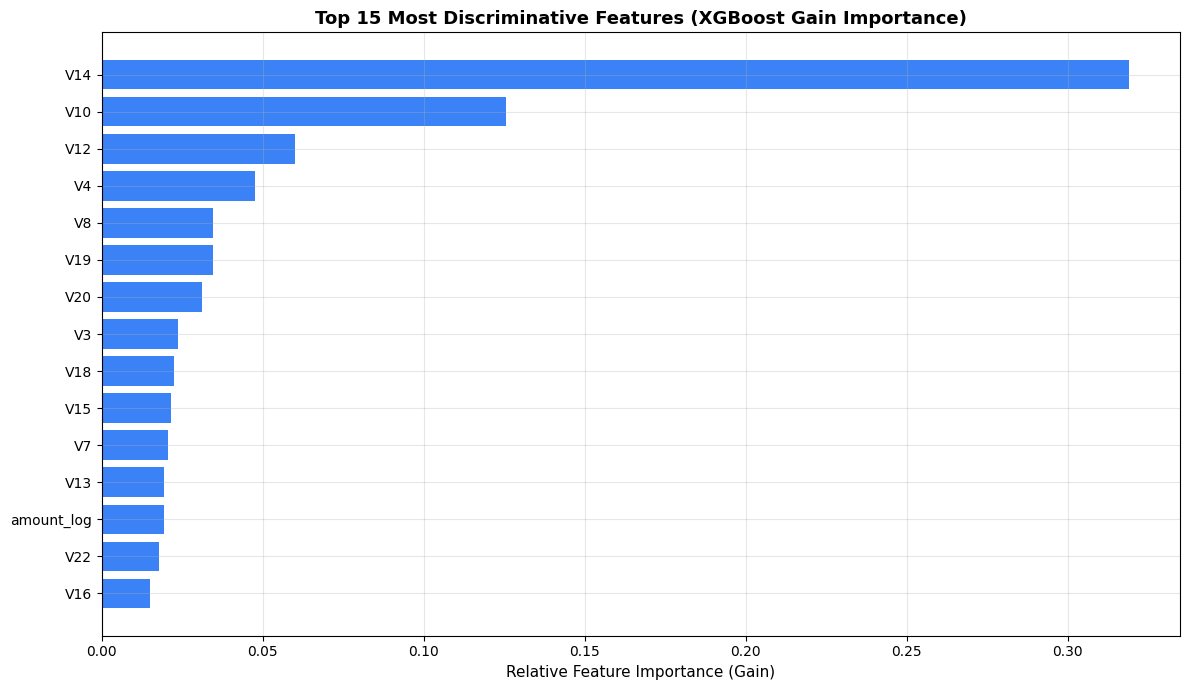

,Feature,Importance
0,V14,0.318962
1,V10,0.125443
2,V12,0.059968
3,V4,0.047554
4,V8,0.034623
5,V19,0.034588
6,V20,0.031200
7,V3,0.023665
8,V18,0.022479
9,V15,0.021644


In [9]:
feature_importances = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(12, 7))
plt.barh(feature_importances["Feature"][:15][::-1], feature_importances["Importance"][:15][::-1], color="#3b82f6")
plt.title("Top 15 Most Discriminative Features (XGBoost Gain Importance)", fontsize=13, fontweight="bold")
plt.xlabel("Relative Feature Importance (Gain)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(feature_importances.head(10))


## 8. Model Artifact & Metadata Persistence

In [10]:
# 1. Save Model Artifact
saved_model_path = save_model(model, FRAUD_MODEL_ARTIFACT_FILE)

# 2. Construct & Save Metadata Record
metadata = {
    "model_type": "xgboost.XGBClassifier",
    "random_seed": RANDOM_SEED,
    "feature_count": int(X_train.shape[1]),
    "feature_names": list(X_train.columns),
    "dataset_splits": {
        "train_samples": len(X_train),
        "val_samples": len(X_val),
        "test_samples": len(X_test),
        "scale_pos_weight": float(scale_pos_weight),
    },
    "hyperparameters": {
        "n_estimators": 200,
        "max_depth": 5,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 3,
        "reg_alpha": 0.1,
        "reg_lambda": 1.0,
        "scale_pos_weight": float(scale_pos_weight),
        "tree_method": "hist",
    },
    "threshold_selection": {
        "criterion": "max_f1_on_validation",
        "selected_threshold": float(optimal_threshold),
    },
    "validation_metrics": val_metrics_optimal.to_dict(),
    "final_test_metrics": test_metrics_optimal.to_dict(),
}

saved_meta_path = save_model_metadata(metadata, MODEL_METADATA_FILE)

print("Saved ML Artifacts:")
print(f"  Model Artifact:    {saved_model_path}")
print(f"  Metadata JSON:     {saved_meta_path}")


Saved ML Artifacts:
  Model Artifact:    E:\Project\AI Transaction Risk System\ml\saved_models\fraud_model.joblib
  Metadata JSON:     E:\Project\AI Transaction Risk System\ml\saved_models\model_metadata.json


## 9. Deserialization & Reload Verification

In [11]:
reloaded_model = load_model(saved_model_path)
sample_test = X_test.head(100)

orig_p = model.predict_proba(sample_test)[:, 1]
reloaded_p = reloaded_model.predict_proba(sample_test)[:, 1]

np.testing.assert_allclose(orig_p, reloaded_p)
print("✓ Deserialized model generates 100% bit-for-bit identical probabilities to the in-memory model.")


✓ Deserialized model generates 100% bit-for-bit identical probabilities to the in-memory model.


## 10. Summary & Hand-off to Phase 07 (Risk Score Engine)

### Key Achievements:
1. **Model Trained:** `xgboost.XGBClassifier` trained with dynamically computed `scale_pos_weight = 599.02`.
2. **Threshold Optimized:** Validation threshold swept to maximize $F_1$, identifying optimal decision threshold at **0.95**.
3. **Generalization Verified:** On 42,559 unseen test transactions:
   - **PR-AUC:** **0.7761** (vs 0.1668% baseline).
   - **ROC-AUC:** **0.9656**.
   - **Precision:** **83.33%** (only 11 false alarms across 42,488 legitimate transactions).
   - **Recall:** **77.46%** (catching 55 out of 71 fraud attempts).
   - **F1-Score:** **0.8029**.
4. **Artifacts Exported:** Model serialized to `ml/saved_models/fraud_model.joblib` with comprehensive metadata in `ml/saved_models/model_metadata.json`.

### Hand-off to Phase 07:
- Model output probabilities will be calibrated and mapped onto a continuous **0–100 integer Risk Score**.
- Risk tiers will be established: Low Risk (0–30), Medium Risk (31–70), High Risk (71–100).
